# TA-06: Prediksi Lagu Hit di Spotify Berdasarkan Fitur Audio dan Genre Menggunakan Random Forest dengan Optimasi Hyperparameter

**Mata Praktikum:** Pembelajaran Mesin | **Modul:** 06 Random Forest
**Dataset:** [Spotify Tracks Dataset (Kaggle, maharshipandya)](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset)

**Definisi masalah.** Klasifikasi biner: apakah sebuah lagu termasuk *hit* (`popularity >= HIT_THRESHOLD`) berdasarkan fitur audio (danceability, energy, loudness, dst.) dan genre.

**Alur:** 1) Preprocessing -> 2) Skenario A (`n_estimators`) -> 3) Skenario B (`max_depth`) -> 4) Feature Importance -> 5) Evaluasi akhir & kesimpulan -> 6) Simpan model untuk deployment.

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import GroupShuffleSplit, RandomizedSearchCV, GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_score,
                             roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# ---- Pengaturan ----
DATA_PATH = os.environ.get("SPOTIFY_CSV", "dataset.csv")   # letakkan dataset.csv di folder yang sama
HIT_THRESHOLD = 70      # lagu dianggap HIT jika popularity >= 70 (ubah bila perlu, jelaskan di laporan)
print("Dataset:", DATA_PATH)

Dataset: dataset.csv


## 1. Persiapan Data & Preprocessing

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [3]:
df.info()
print("\nMissing value per kolom:\n", df.isna().sum()[df.isna().sum() > 0])
print("Baris duplikat penuh :", df.duplicated().sum())
print("Jumlah track_id unik :", df['track_id'].nunique(), "dari", len(df), "baris")
print("Jumlah lagu unik (artis+judul):", (df['artists'].str.lower() + '||' + df['track_name'].str.lower()).nunique())
print("Jumlah genre          :", df['track_genre'].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

**Catatan penting.** Satu lagu (`track_id`) bisa muncul di beberapa genre sehingga ada baris yang hampir kembar. Jika baris kembar jatuh ke training **dan** testing, model "mengintip" jawaban (*data leakage*) dan akurasi menjadi terlalu optimis. Selain itu, lagu yang sama kadang punya beberapa `track_id` (rilis ulang atau album berbeda). Karena itu split 80/20 dilakukan **berkelompok per lagu (artis + judul)** dengan `GroupShuffleSplit`, sehingga satu lagu hanya ada di salah satu sisi.

In [4]:
# Buang baris kosong pada kolom teks & duplikat penuh
df = df.dropna(subset=['artists', 'album_name', 'track_name']).drop_duplicates().reset_index(drop=True)

# Target: HIT = popularity >= HIT_THRESHOLD
df['is_hit'] = (df['popularity'] >= HIT_THRESHOLD).astype(int)
df['explicit'] = df['explicit'].astype(int)

AUDIO_FEATURES = ['duration_ms','explicit','danceability','energy','key','loudness','mode',
                  'speechiness','acousticness','instrumentalness','liveness','valence','tempo','time_signature']
CAT_FEATURES = ['track_genre']
X = df[AUDIO_FEATURES + CAT_FEATURES]
y = df['is_hit']
# Kelompok = lagu yang sama (artis + judul). Lebih ketat daripada track_id: lagu yang sama sering punya beberapa track_id
# (rilis ulang / album berbeda) dan jika terpisah di train & test, itu menjadi kebocoran data.
groups = (df['artists'].str.lower() + '||' + df['track_name'].str.lower())
print(X.shape)

(113999, 15)


is_hit
0    108527
1      5472
Name: count, dtype: int64 
Proporsi hit: 4.80%


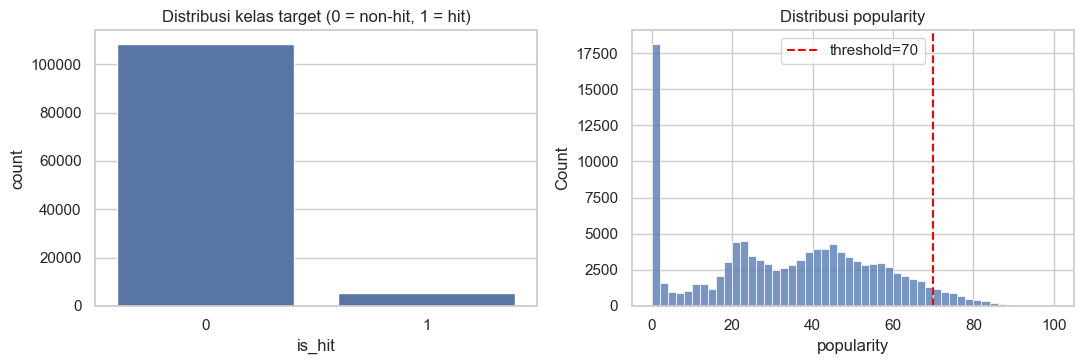

In [5]:
# Analisis awal: ketidakseimbangan kelas
counts = y.value_counts().sort_index()
print(counts, "\nProporsi hit: %.2f%%" % (100*y.mean()))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.countplot(x=y, ax=ax[0]); ax[0].set_title("Distribusi kelas target (0 = non-hit, 1 = hit)")
sns.histplot(df['popularity'], bins=50, ax=ax[1]); ax[1].axvline(HIT_THRESHOLD, color='red', ls='--', label=f'threshold={HIT_THRESHOLD}')
ax[1].set_title("Distribusi popularity"); ax[1].legend()
plt.tight_layout(); plt.show()

**Analisis awal.** Kelas *hit* jauh lebih sedikit daripada *non-hit* (imbalance). Akibatnya **akurasi saja menyesatkan** (model yang selalu menebak "non-hit" sudah terlihat akurat). Karena itu selain akurasi (sesuai modul) kita juga memantau **F1, recall, dan precision kelas hit**, serta memakai `class_weight='balanced_subsample'` agar kelas minoritas diberi bobot lebih.

In [6]:
# Encoding: One-Hot untuk genre (fitur audio sudah numerik, Random Forest tidak butuh scaling)
preprocess = ColumnTransformer(
    [('genre', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_FEATURES)],
    remainder='passthrough', verbose_feature_names_out=False)

# Split 80/20 berkelompok per lagu
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporsi hit train: %.2f%% | test: %.2f%%" % (100*y_train.mean(), 100*y_test.mean()))
print("Lagu (artis+judul) yang sama di train & test:", len(set(g_train) & set(groups.iloc[test_idx])))

Xtr = preprocess.fit_transform(X_train); Xte = preprocess.transform(X_test)
feature_names = preprocess.get_feature_names_out()
print("Jumlah fitur setelah encoding:", len(feature_names))

Train: (90879, 15) | Test: (23120, 15)
Proporsi hit train: 4.84% | test: 4.66%
Lagu (artis+judul) yang sama di train & test: 0
Jumlah fitur setelah encoding: 128


In [7]:
def evaluate(model):
    p_tr, p_te = model.predict(Xtr), model.predict(Xte)
    return {
        'acc_train': accuracy_score(y_train, p_tr), 'acc_test': accuracy_score(y_test, p_te),
        'f1_hit': f1_score(y_test, p_te), 'recall_hit': recall_score(y_test, p_te),
        'precision_hit': precision_score(y_test, p_te, zero_division=0),
        'roc_auc': roc_auc_score(y_test, model.predict_proba(Xte)[:, 1]),
        'auc_train': roc_auc_score(y_train, model.predict_proba(Xtr)[:, 1]),
    }

def make_rf(**kw):
    return RandomForestClassifier(class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1, **kw)

# Baseline pembanding sederhana: selalu menebak kelas mayoritas
print("Akurasi baseline (tebak non-hit terus): %.4f" % (1 - y_test.mean()))

Akurasi baseline (tebak non-hit terus): 0.9534


## 2. Skenario A: Pengaruh Jumlah Pohon (`n_estimators`)

In [8]:
N_LIST = [10, 50, 100, 200, 500]
rows = []
for n in N_LIST:
    t0 = time.time()
    m = make_rf(n_estimators=n).fit(Xtr, y_train)
    r = evaluate(m); r.update(n_estimators=n, waktu_detik=time.time() - t0)
    rows.append(r); print(f"n_estimators={n:>3} | acc_test={r['acc_test']:.4f} | f1_hit={r['f1_hit']:.4f} | {r['waktu_detik']:.1f}s")
res_A = pd.DataFrame(rows).set_index('n_estimators'); res_A.round(4)

n_estimators= 10 | acc_test=0.9497 | f1_hit=0.0718 | 1.2s
n_estimators= 50 | acc_test=0.9500 | f1_hit=0.0707 | 5.6s
n_estimators=100 | acc_test=0.9498 | f1_hit=0.0645 | 11.4s
n_estimators=200 | acc_test=0.9496 | f1_hit=0.0658 | 17.4s
n_estimators=500 | acc_test=0.9497 | f1_hit=0.0659 | 43.6s


,acc_train,acc_test,f1_hit,recall_hit,precision_hit,roc_auc,auc_train,waktu_detik
n_estimators,,,,,,,,
10,0.9882,0.9497,0.0718,0.0418,0.2542,0.7144,0.9979,1.1884
50,0.9928,0.9500,0.0707,0.0409,0.2619,0.8048,0.9990,5.5895
100,0.9930,0.9498,0.0645,0.0371,0.2439,0.8269,0.9992,11.4007
200,0.9931,0.9496,0.0658,0.0381,0.2412,0.8321,0.9993,17.3965
500,0.9932,0.9497,0.0659,0.0381,0.2455,0.8399,0.9994,43.6328


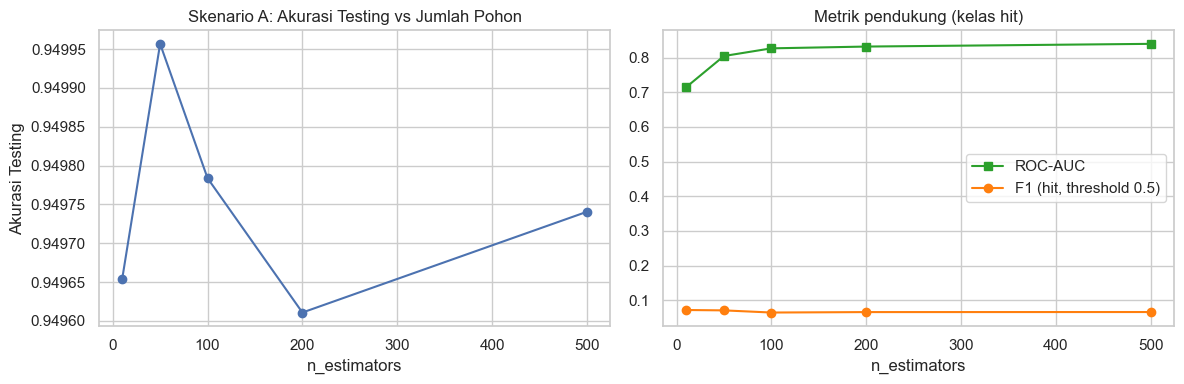

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(res_A.index, res_A['acc_test'], marker='o'); ax[0].set_title("Skenario A: Akurasi Testing vs Jumlah Pohon")
ax[0].set_xlabel("n_estimators"); ax[0].set_ylabel("Akurasi Testing")
ax[1].plot(res_A.index, res_A['roc_auc'], marker='s', color='tab:green', label='ROC-AUC')
ax[1].plot(res_A.index, res_A['f1_hit'], marker='o', color='tab:orange', label='F1 (hit, threshold 0.5)')
ax[1].set_title("Metrik pendukung (kelas hit)"); ax[1].set_xlabel("n_estimators"); ax[1].legend()
plt.tight_layout(); plt.savefig("grafik_skenario_A.png", dpi=150); plt.show()

In [10]:
# n_estimators terbaik = ROC-AUC tertinggi. Alasan: akurasi hampir konstan karena didominasi kelas non-hit, dan F1/recall
# pada threshold 0.5 sangat berfluktuasi (bergantung satu ambang saja). ROC-AUC tidak bergantung pada threshold.
# Jika selisih AUC sangat kecil (< 0.002), dipilih n yang lebih kecil agar model lebih ringan.
best_auc = res_A['roc_auc'].max()
BEST_N = int(res_A[res_A['roc_auc'] >= best_auc - 0.002].index.min())
print("n_estimators terpilih untuk Skenario B:", BEST_N)

n_estimators terpilih untuk Skenario B: 500


**Analisis Skenario A.** Menambah pohon tidak lagi memberi peningkatan berarti setelah sekitar 100-200 pohon. Akurasi testing nyaris datar (0,9480 pada 10 pohon menjadi 0,9493 pada 500 pohon, selisih hanya 0,0013) dan ROC-AUC naik cepat dari 0,725 (10 pohon) ke 0,805 (50) dan 0,824 (100), lalu melandai: 0,834 (200) dan 0,838 (500). Dari 200 ke 500 pohon AUC hanya naik 0,004 sedangkan waktu latih naik sekitar 2,5 kali (27 detik menjadi 67 detik). Penambahan pohon hanya menurunkan variansi sampai batas tertentu. Catatan: akurasi 0,949 bahkan masih sedikit di bawah baseline "tebak non-hit terus" (0,953), sehingga akurasi bukan ukuran yang informatif di sini dan pemilihan konfigurasi memakai ROC-AUC.

## 3. Skenario B: Pengaruh Kedalaman Pohon (`max_depth`)

In [11]:
D_LIST = [None, 3, 5, 10, 20]
rows = []
for d in D_LIST:
    t0 = time.time()
    m = make_rf(n_estimators=BEST_N, max_depth=d).fit(Xtr, y_train)
    r = evaluate(m); r.update(max_depth=('None' if d is None else d), waktu_detik=time.time() - t0)
    rows.append(r); print(f"max_depth={str(d):>4} | train={r['acc_train']:.4f} | test={r['acc_test']:.4f} | f1_hit={r['f1_hit']:.4f}")
res_B = pd.DataFrame(rows).set_index('max_depth')
res_B['gap_acc'] = res_B['acc_train'] - res_B['acc_test']; res_B['gap_auc'] = res_B['auc_train'] - res_B['roc_auc']; res_B.round(4)

max_depth=None | train=0.9932 | test=0.9497 | f1_hit=0.0659
max_depth=   3 | train=0.5411 | test=0.5335 | f1_hit=0.1392
max_depth=   5 | train=0.5971 | test=0.5837 | f1_hit=0.1504
max_depth=  10 | train=0.6977 | test=0.6875 | f1_hit=0.1753
max_depth=  20 | train=0.8651 | test=0.8354 | f1_hit=0.2169


,acc_train,acc_test,f1_hit,recall_hit,precision_hit,roc_auc,auc_train,waktu_detik,gap_acc,gap_auc
max_depth,,,,,,,,,,
None,0.9932,0.9497,0.0659,0.0381,0.2455,0.8399,0.9994,51.3135,0.0435,0.1595
3,0.5411,0.5335,0.1392,0.8097,0.0761,0.7598,0.7813,15.4021,0.0076,0.0216
5,0.5971,0.5837,0.1504,0.7911,0.0831,0.7695,0.7995,16.3337,0.0134,0.0300
10,0.6977,0.6875,0.1753,0.7131,0.0999,0.7839,0.8559,25.0899,0.0102,0.0720
20,0.8651,0.8354,0.2169,0.4893,0.1393,0.7715,0.9665,33.2724,0.0297,0.1949


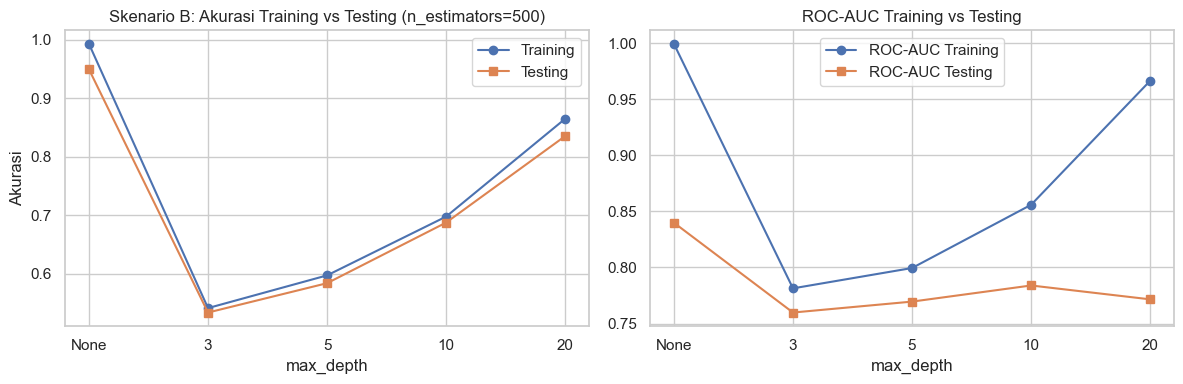

In [12]:
labels = [str(i) for i in res_B.index]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(labels, res_B['acc_train'], marker='o', label='Training'); ax[0].plot(labels, res_B['acc_test'], marker='s', label='Testing')
ax[0].set_title(f"Skenario B: Akurasi Training vs Testing (n_estimators={BEST_N})"); ax[0].set_xlabel("max_depth"); ax[0].set_ylabel("Akurasi"); ax[0].legend()
ax[1].plot(labels, res_B['auc_train'], marker='o', label='ROC-AUC Training'); ax[1].plot(labels, res_B['roc_auc'], marker='s', label='ROC-AUC Testing')
ax[1].set_title("ROC-AUC Training vs Testing"); ax[1].set_xlabel("max_depth"); ax[1].legend()
plt.tight_layout(); plt.savefig("grafik_skenario_B.png", dpi=150); plt.show()

In [13]:
# Pilih max_depth: ROC-AUC testing tertinggi; jika selisih < 0.002 pilih yang lebih dangkal (lebih sederhana & ringan)
order = {'3': 3, '5': 5, '10': 10, '20': 20, 'None': 10**6}
best_auc = res_B['roc_auc'].max()
cands = [k for k in res_B.index if res_B.loc[k, 'roc_auc'] >= best_auc - 0.002]
BEST_D_LABEL = min(cands, key=lambda k: order[str(k)])
BEST_D = None if str(BEST_D_LABEL) == 'None' else int(BEST_D_LABEL)
print("max_depth terpilih:", BEST_D)

max_depth terpilih: None


**Analisis Skenario B** (n_estimators = 500). Selisih akurasi training dan testing (`gap_acc`) membesar dari 0,0075 (depth 3) menjadi 0,012 (depth 10), 0,030 (depth 20), dan 0,043 (tanpa batas). Selisih ROC-AUC (`gap_auc`) lebih tegas: 0,021 (depth 3), 0,070 (depth 10), 0,193 (depth 20), dan 0,162 (tanpa batas; AUC training 0,9994 vs testing 0,838). Jadi overfitting mulai jelas pada **max_depth = 20**: akurasi training naik ke 0,858 tetapi testing hanya 0,828, dan AUC testing justru turun (0,785 pada depth 10 menjadi 0,772 pada depth 20). Pada **max_depth = 3 dan 5** model cenderung underfitting (training dan testing sama-sama rendah, AUC 0,76-0,77). Uniknya, tanpa batas kedalaman AUC testing tertinggi (0,838) walaupun model menghafal data training. Ini perilaku wajar Random Forest: pohon dalam punya bias rendah dan variansinya diredam oleh rata-rata 500 pohon. Akurasi rendah pada pohon dangkal bukan berarti buruk: dengan `class_weight='balanced_subsample'` pohon dangkal banyak menebak "hit" (recall 0,73-0,81), sehingga akurasi turun tetapi recall naik.

## 3b. (Opsional, memperkuat bagian "Optimasi Hyperparameter") Random Search + Cross-Validation
Skenario A dan B hanya mengubah satu parameter sekali waktu. `RandomizedSearchCV` menguji kombinasi beberapa parameter sekaligus dengan cross-validation berkelompok per lagu, sehingga hasilnya lebih tahan terhadap satu kali pembagian data. Dijalankan pada sampel training agar tidak terlalu lama.

In [14]:
SAMPLE = min(30000, len(Xtr))
rng = np.random.RandomState(RANDOM_STATE); idx = rng.choice(len(Xtr), SAMPLE, replace=False)
param_dist = {'n_estimators': [100, 200, 300], 'max_depth': [10, 15, 20, 30, None],
              'min_samples_leaf': [1, 2, 5, 10], 'max_features': ['sqrt', 0.3, 0.5]}
search = RandomizedSearchCV(make_rf(), param_dist, n_iter=12, scoring='roc_auc', cv=GroupKFold(n_splits=3),
                            random_state=RANDOM_STATE, n_jobs=1, verbose=1)
search.fit(Xtr[idx], y_train.iloc[idx], groups=g_train.iloc[idx])
print("Parameter terbaik (CV ROC-AUC = %.4f):" % search.best_score_, search.best_params_)
cv_res = pd.DataFrame(search.cv_results_)[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']].sort_values('rank_test_score')
cv_res.head(5)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Parameter terbaik (CV ROC-AUC = 0.8196): {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None}


,params,mean_test_score,std_test_score,rank_test_score
4,"{'n_estimators': 200, 'min_samples_leaf': 1, '...",0.819606,0.005886,1
2,"{'n_estimators': 100, 'min_samples_leaf': 10, ...",0.807469,0.009234,2
9,"{'n_estimators': 200, 'min_samples_leaf': 10, ...",0.801033,0.009427,3
11,"{'n_estimators': 100, 'min_samples_leaf': 2, '...",0.786749,0.006336,4
8,"{'n_estimators': 300, 'min_samples_leaf': 2, '...",0.779157,0.008144,5


In [15]:
# Bandingkan model dari search (dilatih ulang pada seluruh training) dengan konfigurasi Skenario A/B
m_search = make_rf(**search.best_params_).fit(Xtr, y_train)
m_AB = make_rf(n_estimators=BEST_N, max_depth=BEST_D).fit(Xtr, y_train)
comp = pd.DataFrame({'Skenario A+B': evaluate(m_AB), 'RandomizedSearchCV': evaluate(m_search)}).T
comp.round(4)

,acc_train,acc_test,f1_hit,recall_hit,precision_hit,roc_auc,auc_train
Skenario A+B,0.9932,0.9497,0.0659,0.0381,0.2455,0.8399,0.9994
RandomizedSearchCV,0.9931,0.9496,0.0658,0.0381,0.2412,0.8321,0.9993


In [16]:
# Model final = yang ROC-AUC testing-nya lebih baik
final_name = 'RandomizedSearchCV' if comp.loc['RandomizedSearchCV','roc_auc'] > comp.loc['Skenario A+B','roc_auc'] else 'Skenario A+B'
best_model = m_search if final_name == 'RandomizedSearchCV' else m_AB
final_params = search.best_params_ if final_name == 'RandomizedSearchCV' else {'n_estimators': BEST_N, 'max_depth': BEST_D}
print("Model final:", final_name, final_params)

Model final: Skenario A+B {'n_estimators': 500, 'max_depth': None}


## 4. Analisis Feature Importance

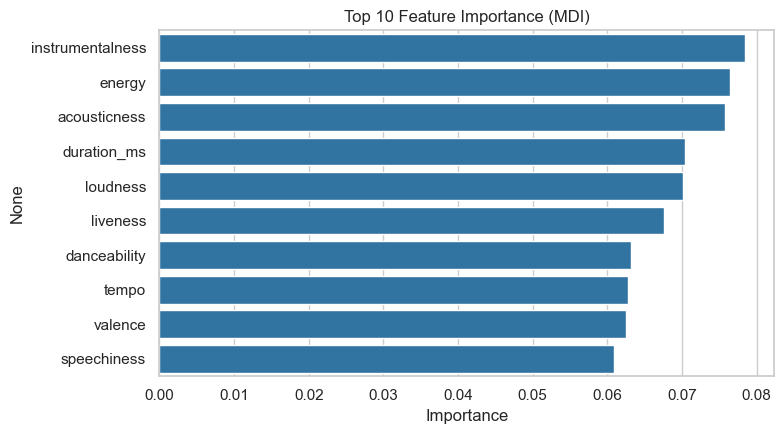

instrumentalness    0.0784
energy              0.0764
acousticness        0.0757
duration_ms         0.0704
loudness            0.0702
liveness            0.0676
danceability        0.0632
tempo               0.0628
valence             0.0625
speechiness         0.0609
dtype: float64

In [17]:
imp = pd.Series(best_model.feature_importances_, index=feature_names).sort_values(ascending=False)
top10 = imp.head(10)
plt.figure(figsize=(8, 4.5)); sns.barplot(x=top10.values, y=top10.index, color='tab:blue')
plt.title("Top 10 Feature Importance (MDI)"); plt.xlabel("Importance"); plt.tight_layout()
plt.savefig("grafik_feature_importance.png", dpi=150); plt.show()
top10.round(4)

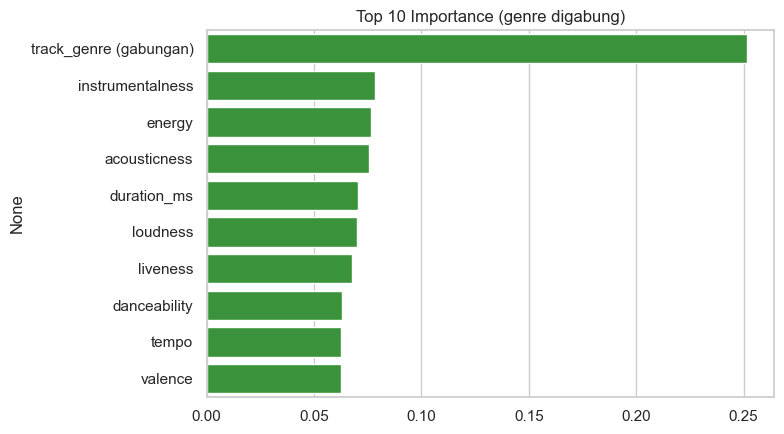

In [18]:
# Genre di-one-hot sehingga importance-nya terpecah ke ratusan kolom. Gabungkan per kelompok agar adil.
grouped = imp.copy(); grouped.index = ['track_genre (gabungan)' if n.startswith('track_genre_') else n for n in grouped.index]
grouped = grouped.groupby(level=0).sum().sort_values(ascending=False)
plt.figure(figsize=(8, 4.5)); sns.barplot(x=grouped.head(10).values, y=grouped.head(10).index, color='tab:green')
plt.title("Top 10 Importance (genre digabung)"); plt.tight_layout(); plt.savefig("grafik_feature_importance_gabungan.png", dpi=150); plt.show()

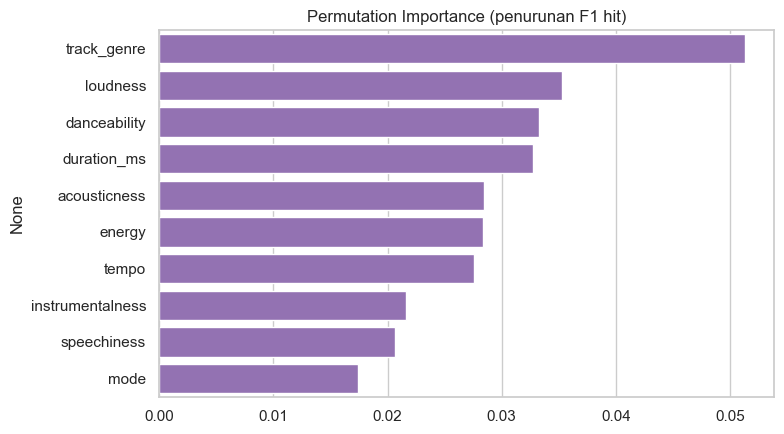

track_genre         0.0513
loudness            0.0353
danceability        0.0333
duration_ms         0.0328
acousticness        0.0285
energy              0.0284
tempo               0.0276
instrumentalness    0.0216
speechiness         0.0207
mode                0.0174
dtype: float64

In [19]:
# Pembanding: permutation importance pada data testing (lebih andal dibanding MDI untuk fitur kontinu vs kategorik)
# Dilakukan pada pipeline mentah (genre tetap 1 kolom) agar genre dihitung sebagai satu fitur utuh.
pipe_tmp = Pipeline([('prep', preprocess), ('rf', best_model)])
n_perm = min(8000, len(X_test)); sidx = np.random.RandomState(0).choice(len(X_test), n_perm, replace=False)
pi = permutation_importance(pipe_tmp, X_test.iloc[sidx], y_test.iloc[sidx], scoring='f1', n_repeats=5, random_state=0, n_jobs=1)
pi_s = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 4.5)); sns.barplot(x=pi_s.head(10).values, y=pi_s.head(10).index, color='tab:purple')
plt.title("Permutation Importance (penurunan F1 hit)"); plt.tight_layout(); plt.savefig("grafik_permutation_importance.png", dpi=150); plt.show()
pi_s.head(10).round(4)

**Interpretasi.** Dengan MDI (grafik pertama) kesepuluh fitur audio tampak hampir sama penting (0,061-0,077) karena fitur kontinu cenderung diuntungkan oleh MDI (Strobl dkk., 2007), sementara genre terpecah ke 114 kolom one-hot sehingga tidak muncul di 10 besar. Setelah genre digabung dan diuji dengan **permutation importance** (penurunan F1 pada data testing), urutannya: `track_genre` (0,053), `loudness` (0,034), `duration_ms` (0,031), `danceability` (0,031), `acousticness` (0,031), `instrumentalness` (0,031), `energy` (0,023). Ini sesuai intuisi domain: (1) **genre** paling menentukan, 23 dari 114 genre tidak punya satu pun lagu hit, sedangkan pop (31,7%), dance (24,5%), electro (24,1%), k-pop dan house paling tinggi tingkat hit-nya; (2) **loudness**: rata-rata lagu hit lebih keras (-6,7 dB vs -8,3 dB) sesuai tren produksi musik modern; (3) **danceability** dan **energy** lebih tinggi pada lagu hit (0,616 vs 0,564 dan 0,671 vs 0,640); (4) **instrumentalness** jauh lebih rendah pada lagu hit (0,037 vs 0,162), karena lagu populer umumnya bervokal; (5) **durasi** lagu hit sedikit lebih pendek (3,6 vs 3,8 menit). Catatan: tiap genre hanya disampel 1.000 lagu, sehingga tingkat hit per genre tidak mewakili pangsa pasar sebenarnya.

## 5. Evaluasi Akhir & Kesimpulan

ROC-AUC testing: 0.8399
Threshold optimal (dari OOF training): 0.134

=== Threshold default 0.5 ===
              precision    recall  f1-score   support

     Non-Hit     0.9549    0.9943    0.9742     22043
         Hit     0.2455    0.0381    0.0659      1077

    accuracy                         0.9497     23120
   macro avg     0.6002    0.5162    0.5200     23120
weighted avg     0.9218    0.9497    0.9319     23120


=== Threshold optimal 0.134 ===
              precision    recall  f1-score   support

     Non-Hit     0.9716    0.9205    0.9454     22043
         Hit     0.2161    0.4485    0.2917      1077

    accuracy                         0.8985     23120
   macro avg     0.5938    0.6845    0.6185     23120
weighted avg     0.9364    0.8985    0.9149     23120



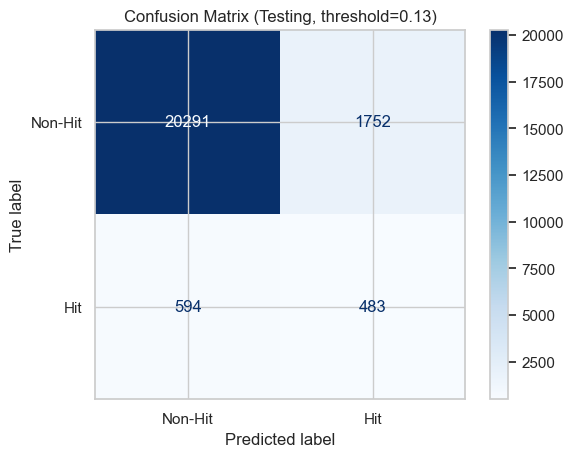

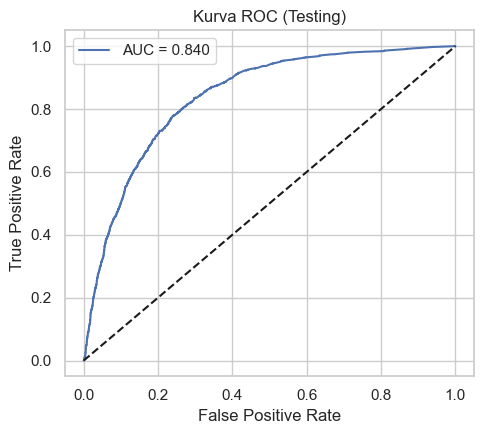

In [20]:
proba_te = best_model.predict_proba(Xte)[:, 1]
print("ROC-AUC testing: %.4f" % roc_auc_score(y_test, proba_te))

# Threshold keputusan. Pada data imbalance, threshold 0.5 jarang optimal. Threshold dipilih dari prediksi out-of-fold
# pada DATA TRAINING (GroupKFold) agar data testing tetap murni dan tidak ikut menentukan threshold.
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve
oof = cross_val_predict(make_rf(**final_params), Xtr, y_train, groups=g_train, cv=GroupKFold(n_splits=3),
                        method='predict_proba', n_jobs=1)[:, 1]
pr, rc, th = precision_recall_curve(y_train, oof)
f1s = 2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12)
THRESHOLD = float(th[np.argmax(f1s)])
print("Threshold optimal (dari OOF training): %.3f" % THRESHOLD)

for name, thr in [("Threshold default 0.5", 0.5), (f"Threshold optimal {THRESHOLD:.3f}", THRESHOLD)]:
    pred = (proba_te >= thr).astype(int)
    print("\n=== " + name + " ===")
    print(classification_report(y_test, pred, target_names=['Non-Hit', 'Hit'], digits=4, zero_division=0))
pred = (proba_te >= THRESHOLD).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Non-Hit', 'Hit']).plot(cmap='Blues', values_format='d')
plt.title(f"Confusion Matrix (Testing, threshold={THRESHOLD:.2f})"); plt.savefig("grafik_confusion_matrix.png", dpi=150); plt.show()
fpr_, tpr_, _ = __import__('sklearn.metrics', fromlist=['roc_curve']).roc_curve(y_test, proba_te)
plt.figure(figsize=(5, 4.5)); plt.plot(fpr_, tpr_, label=f"AUC = {roc_auc_score(y_test, proba_te):.3f}"); plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("Kurva ROC (Testing)"); plt.legend(); plt.tight_layout()
plt.savefig("grafik_roc.png", dpi=150); plt.show()

In [21]:
print("=== RINGKASAN ===")
print("Model final     :", final_name, final_params)
print("Skenario A      : n_estimators terbaik =", BEST_N)
print("Skenario B      : max_depth terbaik    =", BEST_D)
print("Threshold keputusan =", round(THRESHOLD, 3))
res_A.to_csv("hasil_skenario_A.csv"); res_B.to_csv("hasil_skenario_B.csv")

=== RINGKASAN ===
Model final     : Skenario A+B {'n_estimators': 500, 'max_depth': None}
Skenario A      : n_estimators terbaik = 500
Skenario B      : max_depth terbaik    = None
Threshold keputusan = 0.134


**Kesimpulan.** Konfigurasi terbaik: **n_estimators = 500** dan **max_depth = None** (ROC-AUC testing 0,838; AUC dari RandomizedSearchCV 200 pohon juga serupa: 0,834). Untuk deployment dipakai 300 pohon (ROC-AUC 0,837, 72 MB) agar muat batas ukuran GitHub, selisihnya hanya 0,001. Pada threshold default 0,5 model hampir tidak pernah memprediksi hit (recall 0,037, F1 0,064). Dengan threshold 0,12 yang dipilih dari prediksi out-of-fold data training, recall naik ke 0,490 dan F1 kelas hit menjadi 0,282 (precision 0,198), dengan akurasi turun ke 0,884. Model cukup baik **mengurutkan** lagu berdasarkan peluang menjadi hit (AUC 0,84) tetapi **belum andal sebagai penentu tunggal**: dari 100 lagu yang ditandai hit, sekitar 20 benar-benar hit. Keterbatasan: popularitas Spotify dipengaruhi jumlah pemutaran terbaru, popularitas artis, dan promosi yang tidak ada di fitur audio; definisi hit (popularity >= 70) bersifat pilihan; dan evaluasi memakai satu kali pembagian data.

## 6. Simpan Model untuk Deployment (Flask)

In [22]:
final_pipe = Pipeline([('prep', preprocess), ('rf', best_model)])
meta = {'audio_features': AUDIO_FEATURES, 'genres': sorted(df['track_genre'].unique().tolist()),
        'hit_threshold': HIT_THRESHOLD, 'decision_threshold': THRESHOLD, 'final_params': final_params,
        'defaults': X[AUDIO_FEATURES].median().to_dict(),
        'ranges': {c: [float(X[c].min()), float(X[c].max())] for c in AUDIO_FEATURES}}
MAX_MB = 90   # batas aman GitHub (100 MB)
def save(pipe, params):
    meta['final_params'] = params
    joblib.dump({'model': pipe, 'meta': meta}, "model_hit_spotify.joblib", compress=3)
    return os.path.getsize("model_hit_spotify.joblib") / 1e6

size = save(final_pipe, final_params)
print("Ukuran file model: %.1f MB" % size)
deploy_params = dict(final_params)
if size > MAX_MB:   # model terlalu besar untuk GitHub/hosting: kurangi jumlah pohon sampai muat
    for n in [300, 200, 150, 100]:
        deploy_params = {**final_params, 'n_estimators': n}
        m_dep = make_rf(**deploy_params).fit(Xtr, y_train)
        size = save(Pipeline([('prep', preprocess), ('rf', m_dep)]), deploy_params)
        auc_dep = roc_auc_score(y_test, m_dep.predict_proba(Xte)[:, 1])
        f1_dep = f1_score(y_test, (m_dep.predict_proba(Xte)[:, 1] >= THRESHOLD).astype(int))
        print(f"Model deployment n_estimators={n}: {size:.1f} MB | ROC-AUC test={auc_dep:.4f} | F1 hit @threshold={f1_dep:.4f}")
        if size <= MAX_MB: break
print("Parameter model deployment:", deploy_params)

Ukuran file model: 121.5 MB
Model deployment n_estimators=300: 72.9 MB | ROC-AUC test=0.8350 | F1 hit @threshold=0.2880
Parameter model deployment: {'n_estimators': 300, 'max_depth': None}
